In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard Library Imports

# ─────────────────────────────────────────────────────────────────────────────
# Third-Party Imports
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import List

# Define Seaborn style
def set_academic_style():
    
    # Color Universal Design Palette
    color_palette = [
        "#377eb8",  # azul
        "#ff7f00",  # naranja
        "#4daf4a",  # verde
        "#f781bf",  # rosa
        "#a65628",  # marrón
        "#984ea3",  # púrpura
        "#999999",  # gris
        "#e41a1c",  # rojo
        "#dede00"   # amarillo
    ]

    # Style
    sns.set(
        style="whitegrid",
        palette=color_palette,
        context="paper",
        font_scale=1.5
    )

    # Additional Matplotlib Config
    plt.rcParams.update({
        "figure.figsize": (10, 6),
        "axes.titlesize": 18,
        "axes.labelsize": 14,
        "axes.labelweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 12,
        "legend.title_fontsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "savefig.dpi": 300,
        "savefig.format": "pdf"
    })

set_academic_style()


# Input

In [2]:
def datasetsCreator(csv_files, calibrations):
    # Leer y procesar cada archivo
    datasets: List[pl.DataFrame] = []
    for filepath in csv_files:
        df: pl.DataFrame = pl.read_csv(filepath)
        df = df.with_columns([
            (
                (pl.col("timestamp") - pl.col("timestamp").min())
                .cast(pl.Duration("ns")) + pl.lit(0).cast(pl.Datetime("ns"))
            ).alias("timestamp"),
            pl.col("value").cast(pl.Int64)
        ])
        # Filter PTP metrics
        df_ptp = df.filter(
            pl.col("metric").str.contains("PPS") | 
            pl.col("metric").str.contains("offset")
            )

        # PTP Correspondence
        ptp_map = {
            "PPS_3_PPSAnalyzer": "TimeStick_hw_offset",
            "PPS_4_PPSAnalyzer": "Intel710_hw_offset",
            "PPS_5_PPSAnalyzer": "Intel810_hw_offset",
            "offset_TimeStick_PTP_Log": "TimeStick_sw_offset",
            "offset_Intel710_PTP_Log": "Intel710_sw_offset",
            "offset_Intel810_PTP_Log": "Intel810_sw_offset",
        }

        # Name Replacement
        df_ptp = df_ptp.with_columns(
            pl.col("metric").replace(ptp_map).alias("PTP_metric"),
            pl.col("value").alias("offset_ns")
        ).drop("metric", "value")

        # Hardware PTP Dataframe
        df_hw_ptp = df_ptp.filter(
            pl.col("PTP_metric").str.contains("hw")
        ).rename({
            "offset_ns": "offset_hw_ns",
            "PTP_metric":"PTP_client",
        }).with_columns(
            pl.col("PTP_client").replace(
                {
                    "TimeStick_hw_offset": "TimeStick",
                    "Intel710_hw_offset": "Intel 710",
                    "Intel810_hw_offset": "Intel 810",
                }
            )
        )
        
        df_hw_ptp_calibrated = df_hw_ptp.with_columns(
            pl.when(pl.col("PTP_client") == "TimeStick")
            .then(pl.col("offset_hw_ns") - calibrations[0])
            .otherwise(
                pl.when(pl.col("PTP_client") == "Intel 710")
                .then(pl.col("offset_hw_ns") - calibrations[1])
                .otherwise(
                    pl.col("offset_hw_ns") - calibrations[2]
                )    
            )
        )
        datasets.append(df_hw_ptp_calibrated)
    return datasets

def load_datasets(base_dir: str, prefix: str, durations: List[int], suffix: str, calibrations: List[int]) -> List[List[pl.DataFrame]]:
    all_datasets: List[List[pl.DataFrame]] = []
    for duration in durations:
        time_label = f"T{duration}"
        dir_path = Path(f"{base_dir}/{prefix}-{time_label}-{suffix}")
        pattern = f"{prefix}-{time_label}-{suffix}_*.csv"
        csv_files: List[Path] = list(dir_path.glob(pattern))
        datasets: List[pl.DataFrame] = datasetsCreator(csv_files, calibrations)
        all_datasets.append(datasets)
    return all_datasets

# WE1

In [3]:
loads = [25, 75]
calibrations = [162, 325, -35]
# Traffic Model 1 (Little Packets majority)
we1_dataset_L25_SPTM = load_datasets("../output/Ly3_WE1", "Ly3_WE1_L25", [5], "TM1", calibrations)[0][0]
we1_dataset_L75_SPTM = load_datasets("../output/Ly3_WE1", "Ly3_WE1_L75", [5], "TM1", calibrations)[0][0]

# Traffic Model 2 (Big Packets majority)
we1_dataset_L25_LPTM = load_datasets("../output/Ly3_WE1", "Ly3_WE1_L25", [5], "TM2", calibrations)[0][0]
we1_dataset_L75_LPTM = load_datasets("../output/Ly3_WE1", "Ly3_WE1_L75", [5], "TM2", calibrations)[0][0]


In [4]:
from typing import Optional
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter


def violinplot_offset_by_client(
    df: pl.DataFrame,
    ax: plt.Axes,
    title: Optional[str] = None,
    show_legend: bool = False
) -> None:

    # Obtener clientes únicos
    clients_sorted = ["TimeStick","Intel 710","Intel 810"]

    # Paleta de colores consistente
    palette = plt.cm.tab10.colors  # 10 colores estándar de Matplotlib

    # Crear violines
    for i, client in enumerate(clients_sorted):
        values = df.filter(pl.col("PTP_client") == client)["offset_hw_ns"].to_list()

        parts = ax.violinplot(
            values,
            positions=[i],
            showmeans=False,
            showmedians=True,
            showextrema=True
        )

        # Poner color
        for pc in parts['bodies']:
            pc.set_facecolor(palette[i % len(palette)])
            pc.set_edgecolor('black')
            pc.set_alpha(0.7)

        # Mediana y extremos
        parts['cmedians'].set_color('black')
        parts['cmaxes'].set_color('black')
        parts['cmins'].set_color('black')

    # Etiquetas del eje X
    ax.set_xticklabels([], fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y/1000)}"))

    # Título
    ax.set_title(title or "", fontweight='bold')

    # Leyenda manual
    if show_legend:
        legend_handles = [
            Patch(facecolor=palette[i % len(palette)], edgecolor="black", label=str(client))
            for i, client in enumerate(clients_sorted)
        ]

        ax.legend(
            handles=legend_handles,
            title="Cliente",
            bbox_to_anchor=(1.05, 1),
            loc="upper left"
        )


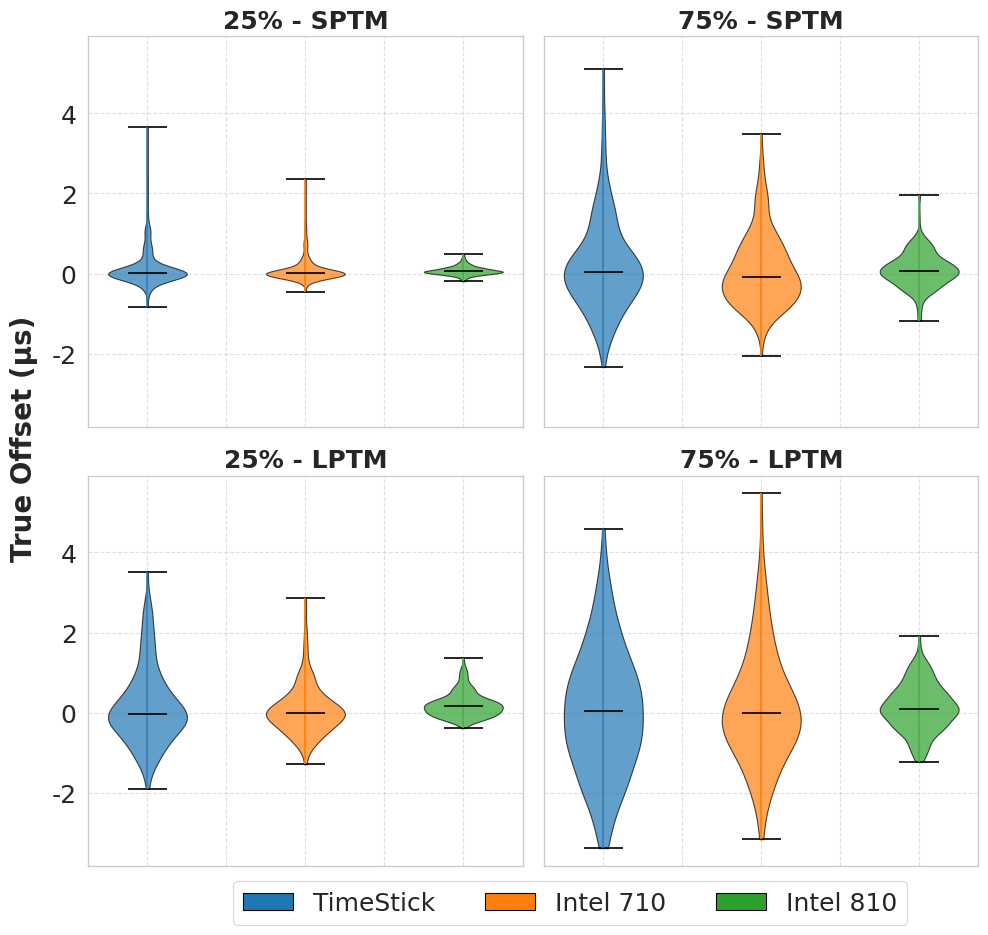

In [5]:

from typing import List, Optional
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import polars as pl


def plot_violin_grid(
    datasets: List[pl.DataFrame],
    titles: List[str],
    global_ylabel: Optional[str] = None
) -> plt.Figure:

    fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
    ax_list = axes.flatten()

    # Paleta única para toda la figura
    palette = plt.cm.tab10.colors

    # --- PRIMER PASO: Pintar violines sin leyenda ---
    for ax, df, title in zip(ax_list, datasets, titles):
        violinplot_offset_by_client(
            df=df,
            ax=ax,
            title=title,
            show_legend=False   # La leyenda será global
        )

    # --- SEGUNDO PASO: Crear leyenda global ---
    # Obtener todos los clientes existentes en todos los datasets
    all_clients_sorted = ["TimeStick","Intel 710","Intel 810"]

    legend_handles = [
        Patch(facecolor=palette[i % len(palette)],
              edgecolor="black",
              label=str(client))
        for i, client in enumerate(all_clients_sorted)
    ]

    
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        fontsize=18,
        frameon=True,
        ncol=len(all_clients_sorted),
        bbox_to_anchor=(0.57, 0)
    )


    # --- TÍTULOS GLOBALES ---
    if global_ylabel:
        fig.text(0.01, 0.5, global_ylabel, va="center", rotation="vertical", fontsize=20, fontweight='bold')

    fig.tight_layout(rect=(0.03, 0.05, 1, 0.95))

    plt.savefig("Experiment1.pdf", format="pdf", bbox_inches='tight', pad_inches=0.05)

fig = plot_violin_grid(
    datasets=[
        we1_dataset_L25_SPTM,
        we1_dataset_L75_SPTM,
        we1_dataset_L25_LPTM,
        we1_dataset_L75_LPTM
    ],
    titles=["25% - SPTM", "75% - SPTM", "25% - LPTM", "75% - LPTM"],
    global_ylabel="True Offset (µs)"
)


